# Q-Portfolio: Google Colab Workflow

This notebook is the Colab-only version of the complete Q-Portfolio pipeline. It loads or creates OHLCV data, trains classical and quantum classifiers, builds allocations, runs a walk-forward backtest, and saves the same CSV and PNG artifacts as the original project.

Set `DATA_MODE` to `market` to download data with yfinance, or leave it as `sample` for deterministic sample data.

In [2]:
!pip -q install numpy pandas scikit-learn scipy yfinance matplotlib plotly pennylane pennylane-lightning joblib

import os
import time
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path('/content/q-portfolio')
RESULTS = ROOT / 'results'
MODELS = ROOT / 'models'
RESULTS.mkdir(parents=True, exist_ok=True)
MODELS.mkdir(parents=True, exist_ok=True)
ASSETS = ['AAPL', 'MSFT', 'GOOGL', 'AMZN', 'NVDA']
FEATURES = ['momentum', 'volatility', 'rsi', 'moving_average_ratio', 'rolling_mean_return', 'volume_change']
QUANTUM_FEATURES = ['momentum', 'volatility', 'rsi', 'moving_average_ratio']
SEED = 42
DATA_MODE = 'sample'  # 'sample' or 'market'
EPOCHS = 20
INITIAL_CAPITAL = 100000.0
np.random.seed(SEED)
print(f'Colab root: {ROOT}')


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Colab root: \content\q-portfolio


## Data loading
The loader accepts uploaded CSVs from `/content/q-portfolio/data/sample` or `/content/q-portfolio/data/raw`. If they are absent, sample mode creates deterministic OHLCV data; market mode downloads with yfinance.

In [3]:
def synthetic_ohlcv(ticker, periods=750, seed=SEED):
    rng = np.random.default_rng(seed + ASSETS.index(ticker))
    dates = pd.bdate_range('2021-01-01', periods=periods)
    drift = 0.00025 + 0.00008 * ASSETS.index(ticker)
    close = 100 * np.exp(np.cumsum(rng.normal(drift, 0.012, periods)))
    open_ = close * (1 + rng.normal(0, 0.002, periods))
    high = np.maximum(open_, close) * (1 + rng.uniform(0, 0.012, periods))
    low = np.minimum(open_, close) * (1 - rng.uniform(0, 0.012, periods))
    volume = rng.integers(1_000_000, 8_000_000, periods)
    return pd.DataFrame({'Open': open_, 'High': high, 'Low': low, 'Close': close, 'Volume': volume}, index=dates)

def load_data(mode=DATA_MODE, tickers=ASSETS):
    folder = ROOT / 'data' / ('sample' if mode == 'sample' else 'raw')
    folder.mkdir(parents=True, exist_ok=True)
    data = {}
    for ticker in tickers:
        path = folder / f'{ticker.replace(".", "_")}.csv'
        if path.exists():
            try:
                data[ticker] = pd.read_csv(path, index_col=0, parse_dates=True).dropna(how='all')
            except Exception as exc:
                print(f'Could not read {path}: {exc}')
    missing = [ticker for ticker in tickers if ticker not in data]
    if mode == 'market' and missing:
        import yfinance as yf
        for ticker in missing:
            downloaded = yf.download(ticker, period='5y', auto_adjust=False, progress=False)
            if not downloaded.empty:
                if isinstance(downloaded.columns, pd.MultiIndex):
                    downloaded.columns = downloaded.columns.get_level_values(0)
                data[ticker] = downloaded[['Open', 'High', 'Low', 'Close', 'Volume']].dropna()
    if mode == 'sample':
        for ticker in missing:
            data[ticker] = synthetic_ohlcv(ticker)
    if not data:
        raise ValueError('No usable OHLCV data found.')
    return data

data = load_data()
print({ticker: frame.shape for ticker, frame in data.items()})
display(next(iter(data.values())).head())

{'AAPL': (750, 5), 'MSFT': (750, 5), 'GOOGL': (750, 5), 'AMZN': (750, 5), 'NVDA': (750, 5)}


,Open,High,Low,Close,Volume
2021-01-01,100.393724,101.382269,99.220374,100.391425,7285310
2021-01-04,99.111777,99.457643,98.269504,99.171134,3658035
2021-01-05,99.890062,100.526641,99.158241,100.093264,2651290
2021-01-06,101.669597,101.884757,100.880919,101.254705,7469962
2021-01-07,99.289590,99.846586,98.581221,98.936354,5710914


## Features and chronological split

In [4]:
def make_features(df):
    close = df['Close'].astype(float)
    ret = close.pct_change()
    volume = df.get('Volume', pd.Series(0, index=df.index)).astype(float)
    moving_average = close.rolling(20, min_periods=5).mean()
    delta = close.diff()
    gain = delta.clip(lower=0).rolling(14, min_periods=5).mean()
    loss = -delta.clip(upper=0).rolling(14, min_periods=5).mean()
    relative_strength = gain / loss.replace(0, np.nan)
    rsi = 100 - 100 / (1 + relative_strength)
    features = pd.DataFrame({
        'daily_return': ret,
        'volatility': ret.rolling(20, min_periods=5).std(),
        'momentum': close.pct_change(10),
        'rsi': rsi,
        'moving_average': moving_average,
        'moving_average_ratio': close / moving_average - 1,
        'rolling_mean_return': ret.rolling(10, min_periods=5).mean(),
        'volume_change': volume.pct_change().replace([np.inf, -np.inf], np.nan),
    }, index=df.index)
    features['target'] = (ret.shift(-1) > 0).astype(int)
    return features.replace([np.inf, -np.inf], np.nan).dropna()

def chronological_split(frame, train_ratio=0.70, validation_ratio=0.15):
    first = int(len(frame) * train_ratio)
    second = int(len(frame) * (train_ratio + validation_ratio))
    return frame.iloc[:first], frame.iloc[first:second], frame.iloc[second:]

feature_map = {ticker: make_features(frame) for ticker, frame in data.items()}
splits = {ticker: chronological_split(frame) for ticker, frame in feature_map.items()}
display(feature_map[ASSETS[0]].tail())

,daily_return,volatility,momentum,rsi,moving_average,moving_average_ratio,rolling_mean_return,volume_change,target
2023-11-10,0.011486,0.012374,-0.020606,46.688377,80.186483,-0.013108,-0.001963,0.041629,1
2023-11-13,0.022061,0.013366,-0.008547,51.413071,80.190452,0.008614,-0.000720,-0.710478,1
2023-11-14,0.006466,0.013271,-0.012000,53.841308,80.182179,0.015241,-0.001071,2.123009,0
2023-11-15,-0.004202,0.012942,0.002910,51.562008,80.211220,0.010609,0.000409,-0.281843,0
2023-11-16,-0.010413,0.012807,0.019340,48.005407,80.250763,-0.000407,0.002004,0.718496,0


## Classical and quantum models

In [5]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

def metrics(y_true, predictions, probabilities):
    result = {'accuracy': accuracy_score(y_true, predictions), 'precision': precision_score(y_true, predictions, zero_division=0), 'recall': recall_score(y_true, predictions, zero_division=0), 'f1': f1_score(y_true, predictions, zero_division=0), 'confusion_matrix': confusion_matrix(y_true, predictions).tolist()}
    try:
        result['roc_auc'] = roc_auc_score(y_true, probabilities)
    except ValueError:
        result['roc_auc'] = float('nan')
    return result

def train_classical(x, y):
    model = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), LogisticRegression(random_state=SEED, max_iter=1000))
    return model.fit(x, y)

import pennylane as qml
from pennylane import numpy as pnp

class QuantumClassifier:
    def __init__(self, layers=2, epochs=EPOCHS, seed=SEED, stepsize=0.08):
        self.layers, self.epochs, self.seed = layers, epochs, seed
        self.loss_history = []
        for backend in ['lightning.qubit', 'default.qubit']:
            try:
                self.dev = qml.device(backend, wires=4)
                self.backend = backend
                break
            except Exception:
                continue
        else:
            raise RuntimeError('Could not initialize a PennyLane backend')
        layer_count = layers
        @qml.qnode(self.dev, interface='autograd')
        def circuit(x, weights):
            for index in range(4):
                qml.RY(x[index], wires=index)
            for layer in range(layer_count):
                for index in range(4):
                    qml.RY(weights[layer, index, 0], wires=index)
                    qml.RZ(weights[layer, index, 1], wires=index)
                for index in range(4):
                    qml.CNOT(wires=[index, (index + 1) % 4])
            return qml.expval(qml.PauliZ(0))
        self.circuit = circuit
        self.weights = pnp.array(np.random.default_rng(seed).normal(0, 0.1, (layers, 4, 2)), requires_grad=True)
        self.stepsize = stepsize

    def _scale(self, x):
        return np.pi * np.tanh(np.asarray(x, dtype=float))

    def fit(self, x, y, progress_callback=None):
        x = pnp.array(self._scale(x)); y = pnp.array(np.asarray(y, dtype=float) * 2 - 1)
        if len(x) > 128:
            indices = np.random.default_rng(self.seed).choice(len(x), 128, replace=False)
            x, y = x[indices], y[indices]
        optimizer = qml.AdamOptimizer(self.stepsize)
        def loss(weights):
            return pnp.mean(pnp.stack([(self.circuit(row, weights) - target) ** 2 for row, target in zip(x, y)]))
        for epoch in range(self.epochs):
            self.weights, value = optimizer.step_and_cost(loss, self.weights)
            self.loss_history.append(float(value))
            if progress_callback:
                progress_callback(epoch + 1, self.epochs, float(value))
        return self

    def predict_proba(self, x):
        expectation = np.array([float(self.circuit(pnp.array(row), self.weights)) for row in self._scale(x)])
        probability = np.clip((1 - expectation) / 2, 0, 1)
        return np.c_[1 - probability, probability]

    def predict(self, x):
        return (self.predict_proba(x)[:, 1] >= 0.5).astype(int)

## Train, evaluate, and save models

In [6]:
rows, signals, models, test_frames = [], {}, {}, {}
for asset_index, ticker in enumerate(ASSETS):
    if ticker not in splits:
        continue
    train_frame, validation_frame, test_frame = splits[ticker]
    test_frames[ticker] = test_frame
    print(f'{ticker}: training classical model')
    classical_started = time.perf_counter()
    classical = train_classical(train_frame[FEATURES], train_frame.target)
    print(f'{ticker}: training quantum model ({EPOCHS} epochs)')
    quantum_started = time.perf_counter()
    quantum = QuantumClassifier(epochs=EPOCHS).fit(train_frame[QUANTUM_FEATURES], train_frame.target, progress_callback=lambda epoch, total, loss: print(f'  epoch {epoch}/{total}, loss={loss:.5f}'))
    models[ticker] = (classical, quantum)
    np.save(MODELS / f'{ticker}_quantum_parameters.npy', np.asarray(quantum.weights))
    for name, model, columns, started in [('classical', classical, FEATURES, classical_started), ('quantum', quantum, QUANTUM_FEATURES, quantum_started)]:
        predictions = model.predict(test_frame[columns])
        probabilities = model.predict_proba(test_frame[columns])[:, 1]
        rows.append({'asset': ticker, 'model': name, 'runtime_seconds': time.perf_counter() - started, **metrics(test_frame.target, predictions, probabilities)})
        for date, probability in zip(test_frame.index, probabilities):
            signals.setdefault(date, {})[(ticker, 'qml' if name == 'quantum' else 'classical')] = float(probability)

model_comparison = pd.DataFrame(rows)
model_comparison.to_csv(RESULTS / 'model_comparison.csv', index=False)
joblib.dump(models[ASSETS[0]][0], MODELS / 'classical.joblib')
display(model_comparison)

AAPL: training classical model
AAPL: training quantum model (20 epochs)
  epoch 1/20, loss=1.65131
  epoch 2/20, loss=1.57654
  epoch 3/20, loss=1.46200
  epoch 4/20, loss=1.32221
  epoch 5/20, loss=1.18245
  epoch 6/20, loss=1.06882
  epoch 7/20, loss=0.99992
  epoch 8/20, loss=0.98057
  epoch 9/20, loss=0.99956
  epoch 10/20, loss=1.03221
  epoch 11/20, loss=1.05749
  epoch 12/20, loss=1.06714
  epoch 13/20, loss=1.06272
  epoch 14/20, loss=1.04911
  epoch 15/20, loss=1.03068
  epoch 16/20, loss=1.01160
  epoch 17/20, loss=0.99543
  epoch 18/20, loss=0.98414
  epoch 19/20, loss=0.97790
  epoch 20/20, loss=0.97557
MSFT: training classical model
MSFT: training quantum model (20 epochs)
  epoch 1/20, loss=1.68393
  epoch 2/20, loss=1.60621
  epoch 3/20, loss=1.48757
  epoch 4/20, loss=1.34334
  epoch 5/20, loss=1.19912
  epoch 6/20, loss=1.08097
  epoch 7/20, loss=1.00825
  epoch 8/20, loss=0.98710
  epoch 9/20, loss=1.00674
  epoch 10/20, loss=1.04058
  epoch 11/20, loss=1.06593
  epoc

,asset,model,runtime_seconds,accuracy,precision,recall,f1,confusion_matrix,roc_auc
0,AAPL,classical,8.475281,0.486486,0.456140,0.500000,0.477064,"[[28, 31], [26, 26]]",0.496741
1,AAPL,quantum,8.960868,0.531532,0.000000,0.000000,0.000000,"[[59, 0], [52, 0]]",0.446219
2,MSFT,classical,8.017703,0.540541,0.581818,0.533333,0.556522,"[[28, 23], [28, 32]]",0.521895
3,MSFT,quantum,8.441066,0.459459,0.000000,0.000000,0.000000,"[[51, 0], [60, 0]]",0.511438
4,GOOGL,classical,9.637788,0.531532,0.571429,0.645161,0.606061,"[[19, 30], [22, 40]]",0.498683
5,GOOGL,quantum,10.247624,0.441441,0.000000,0.000000,0.000000,"[[49, 0], [62, 0]]",0.490783
6,AMZN,classical,218.991793,0.495495,0.515625,0.568966,0.540984,"[[22, 31], [25, 33]]",0.501952
7,AMZN,quantum,235.063813,0.477477,0.000000,0.000000,0.000000,"[[53, 0], [58, 0]]",0.537085
8,NVDA,classical,113.148241,0.495495,0.492958,0.636364,0.555556,"[[20, 36], [20, 35]]",0.529870
9,NVDA,quantum,113.967226,0.495495,0.495495,1.000000,0.662651,"[[0, 56], [0, 55]]",0.504545


## Allocation, walk-forward backtest, and risk metrics

In [7]:
from scipy.optimize import minimize

def optimize(expected_returns, covariance, risk_aversion=5, max_weight=0.4):
    expected_returns, covariance = np.asarray(expected_returns, float), np.asarray(covariance, float)
    if len(expected_returns) * max_weight < 1:
        raise ValueError('max_weight too small to fully invest')
    def objective(weights):
        return -(weights @ expected_returns - risk_aversion * (weights @ covariance @ weights))
    result = minimize(objective, np.ones(len(expected_returns)) / len(expected_returns), bounds=[(0, max_weight)] * len(expected_returns), constraints=[{'type': 'eq', 'fun': lambda weights: weights.sum() - 1}], method='SLSQP', options={'maxiter': 500, 'ftol': 1e-12})
    if not result.success:
        raise ValueError(result.message)
    return result.x

def risk_metrics(values, periods=252):
    values = np.asarray(values, float)
    daily = values[1:] / values[:-1] - 1 if len(values) > 1 else np.array([])
    cumulative = np.cumprod(1 + daily)
    peak = np.maximum.accumulate(np.r_[1, cumulative])
    drawdown = np.r_[1, cumulative] / peak - 1
    annual_return = cumulative[-1] ** (periods / len(daily)) - 1 if len(daily) else 0
    volatility = np.std(daily, ddof=1) * np.sqrt(periods) if len(daily) > 1 else 0
    return {'annualized_return': float(annual_return), 'annualized_volatility': float(volatility), 'expected_return': float(annual_return), 'volatility': float(volatility), 'sharpe_ratio': float(annual_return / volatility) if volatility else 0.0, 'max_drawdown': float(drawdown.min()), 'cumulative_return': float(cumulative[-1] - 1) if len(daily) else 0.0, 'daily_returns': daily}

allocation = []
for ticker, frame in data.items():
    classical, quantum = models[ticker]
    latest = feature_map[ticker].iloc[-1]
    probability = float(quantum.predict_proba([latest[QUANTUM_FEATURES]])[0, 1])
    allocation.append({'asset': ticker, 'predicted_direction': int(probability >= 0.5), 'prediction_probability': probability, 'expected_return': (probability - 0.5) * 0.04})
prices = pd.concat([frame.Close.rename(ticker) for ticker, frame in data.items()], axis=1).dropna()
covariance = prices.pct_change().dropna().cov().values
weights = optimize([row['expected_return'] for row in allocation], covariance)
for row, weight in zip(allocation, weights):
    row['portfolio_weight'] = float(weight)
allocation_frame = pd.DataFrame(allocation)
allocation_frame.to_csv(RESULTS / 'portfolio_allocation.csv', index=False)
display(allocation_frame)

,asset,predicted_direction,prediction_probability,expected_return,portfolio_weight
0,AAPL,0,0.409829,-0.003607,2.416426e-16
1,MSFT,0,0.425675,-0.002973,0.000000e+00
2,GOOGL,0,0.472508,-0.001100,2.599919e-01
3,AMZN,0,0.475977,-0.000961,3.400081e-01
4,NVDA,1,0.521711,0.000868,4.000000e-01


In [8]:
def backtest(price_frame, signal_frame, initial_capital=INITIAL_CAPITAL):
    returns = price_frame.pct_change().dropna()
    values = {name: float(initial_capital) for name in ['qml', 'classical', 'equal_weight', 'buy_hold']}
    records = []
    for date, daily_asset_returns in returns.iterrows():
        if date not in signal_frame.index:
            continue
        history = returns.loc[:date].iloc[:-1].tail(60)
        if len(history) < 10:
            continue
        strategy_returns = {}
        for model_name in ['qml', 'classical']:
            probabilities = [float(signal_frame.loc[date, (asset, model_name)]) if (asset, model_name) in signal_frame.columns and pd.notna(signal_frame.loc[date, (asset, model_name)]) else 0.5 for asset in price_frame.columns]
            weights = optimize((np.asarray(probabilities) - 0.5) * 0.04, history.cov().fillna(0).values)
            strategy_returns[model_name] = float(weights @ daily_asset_returns.reindex(price_frame.columns).values)
        strategy_returns['equal_weight'] = float(daily_asset_returns.mean())
        strategy_returns['buy_hold'] = float(daily_asset_returns.mean())
        for name, daily_return in strategy_returns.items():
            values[name] *= 1 + daily_return
            records.append({'date': date, 'strategy': name, 'portfolio_value': values[name], 'daily_return': daily_return})
    frame = pd.DataFrame(records)
    summary = {name: risk_metrics(group.portfolio_value.to_numpy()) for name, group in frame.groupby('strategy')}
    return frame, summary

signal_frame = pd.DataFrame.from_dict(signals, orient='index').sort_index()
backtest_results, backtest_summary = backtest(prices, signal_frame)
backtest_results.to_csv(RESULTS / 'backtest_results.csv', index=False)
summary_frame = pd.DataFrame(backtest_summary).T
runtime_summary = model_comparison.groupby('model')['runtime_seconds'].sum()
summary_frame['runtime_seconds'] = [runtime_summary.get({'qml': 'quantum'}.get(index, index), 0.0) for index in summary_frame.index]
summary_frame = summary_frame.rename(index={'qml': 'quantum'})
summary_frame.to_csv(RESULTS / 'backtest_summary.csv')
comparison = summary_frame.loc[[name for name in ['classical', 'quantum'] if name in summary_frame.index], ['expected_return', 'volatility', 'sharpe_ratio', 'max_drawdown', 'runtime_seconds']].reset_index(names='model')
if {'classical', 'quantum'}.issubset(set(comparison['model'])):
    delta = comparison.set_index('model').loc['quantum'] - comparison.set_index('model').loc['classical']
    comparison = pd.concat([comparison, pd.DataFrame([{'model': 'quantum_minus_classical', **delta.to_dict()}])], ignore_index=True)
comparison.to_csv(RESULTS / 'performance_comparison.csv', index=False)
display(summary_frame.drop(columns=['daily_returns']))
display(comparison)

,annualized_return,annualized_volatility,expected_return,volatility,sharpe_ratio,max_drawdown,cumulative_return,runtime_seconds
buy_hold,0.090325,0.098616,0.090325,0.098616,0.915923,-0.083028,0.038469,0.000000
classical,-0.185943,0.127263,-0.185943,0.127263,-1.461093,-0.160246,-0.085886,358.270806
equal_weight,0.090325,0.098616,0.090325,0.098616,0.915923,-0.083028,0.038469,0.000000
quantum,0.089947,0.117021,0.089947,0.117021,0.768638,-0.104066,0.038312,376.680597


,model,expected_return,volatility,sharpe_ratio,max_drawdown,runtime_seconds
0,classical,-0.185943,0.127263,-1.461093,-0.160246,358.270806
1,quantum,0.089947,0.117021,0.768638,-0.104066,376.680597
2,quantum_minus_classical,0.27589,-0.010242,2.229731,0.05618,18.409791


## Plots and validation

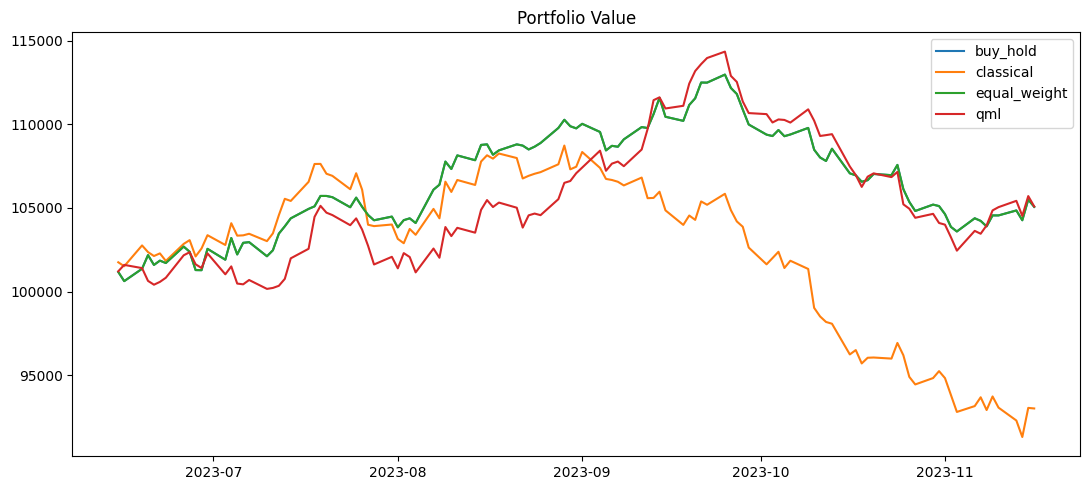

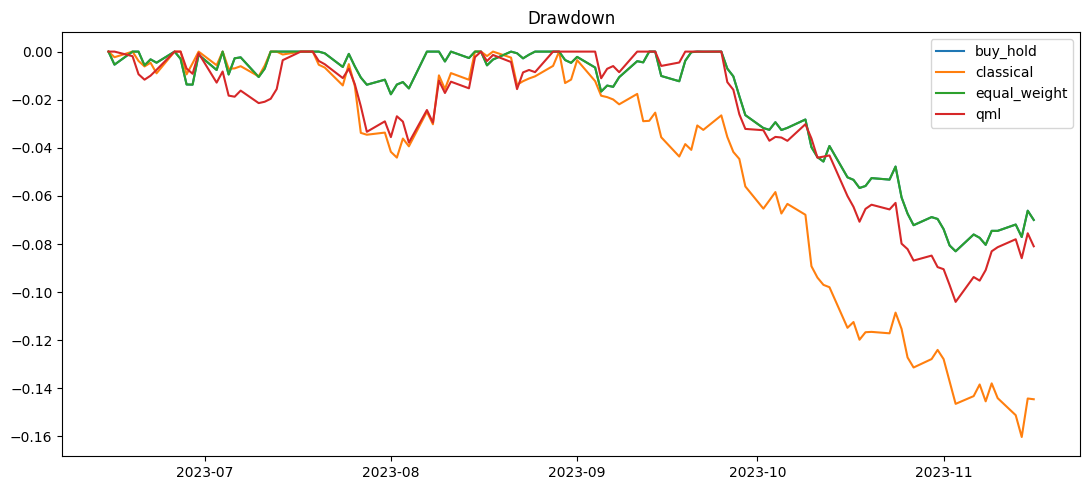

Validation passed.
Results: ['backtest_results.csv', 'backtest_summary.csv', 'drawdown.png', 'model_comparison.csv', 'performance_comparison.csv', 'portfolio_allocation.csv', 'portfolio_value.png']
Models: ['AAPL_quantum_parameters.npy', 'AMZN_quantum_parameters.npy', 'GOOGL_quantum_parameters.npy', 'MSFT_quantum_parameters.npy', 'NVDA_quantum_parameters.npy', 'classical.joblib']


In [9]:
if not backtest_results.empty:
    for column, filename in [('portfolio_value', 'portfolio_value.png'), ('drawdown', 'drawdown.png')]:
        plot_frame = backtest_results.copy()
        if column == 'drawdown':
            plot_frame[column] = plot_frame.groupby('strategy').portfolio_value.transform(lambda values: values / values.cummax() - 1)
        figure, axis = plt.subplots(figsize=(11, 5))
        for strategy, group in plot_frame.groupby('strategy'):
            axis.plot(group.date, group[column], label=strategy)
        axis.set_title(column.replace('_', ' ').title())
        axis.legend()
        figure.tight_layout()
        figure.savefig(RESULTS / filename, dpi=150)
        plt.show()
        plt.close(figure)

assert all(set(frame.target.unique()).issubset({0, 1}) for frame in feature_map.values())
assert np.isclose(sum(row['portfolio_weight'] for row in allocation), 1.0)
assert all(0 <= row['portfolio_weight'] <= 0.4 + 1e-8 for row in allocation)
assert set(['model_comparison.csv', 'portfolio_allocation.csv', 'backtest_results.csv', 'backtest_summary.csv', 'performance_comparison.csv']).issubset({path.name for path in RESULTS.iterdir()})
print('Validation passed.')
print('Results:', sorted(path.name for path in RESULTS.iterdir()))
print('Models:', sorted(path.name for path in MODELS.iterdir()))

## Simple portfolio dashboard

This view summarizes deployed capital, profit or loss, invested stocks, allocation, and risk controls using plain tables and charts.

"Starting capital$100,000.00","Current value$105,087.39","Profit / loss$5,087.39 (5.09%)",Stocks invested3


,Stock,Weight,Signal probability,Expected return
2,GOOGL,26.00%,47.25%,-0.11%
3,AMZN,34.00%,47.60%,-0.10%
4,NVDA,40.00%,52.17%,0.09%


,Risk measure,Value
0,Annual volatility,11.70%
1,Sharpe ratio,0.77
2,Maximum drawdown,-10.41%
3,Largest stock exposure,40.00% (limit: 40.00%)
4,Total invested,100.00%


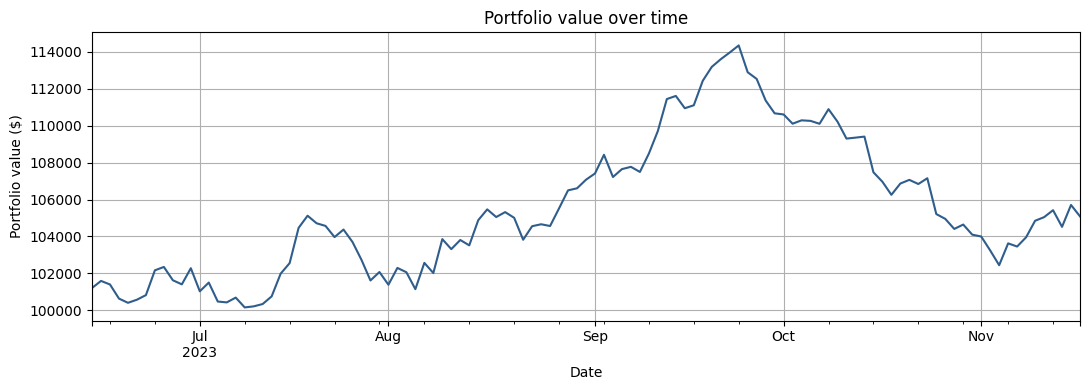

In [13]:
from IPython.display import HTML, display

strategy_name = 'qml'
starting_capital = float(INITIAL_CAPITAL)
strategy_data = backtest_results[backtest_results['strategy'] == strategy_name].sort_values('date')

if strategy_data.empty:
    ending_value = starting_capital
    profit_loss = 0.0
else:
    ending_value = float(strategy_data['portfolio_value'].iloc[-1])
    profit_loss = ending_value - starting_capital
profit_loss_pct = profit_loss / starting_capital if starting_capital else 0.0

invested = allocation_frame[allocation_frame['portfolio_weight'] > 1e-8].copy()
risk_row = summary_frame.loc['quantum'] if 'quantum' in summary_frame.index else pd.Series(dtype=float)
max_exposure = float(allocation_frame['portfolio_weight'].max()) if not allocation_frame.empty else 0.0

profit_color = '#1b6e3c' if profit_loss >= 0 else '#a33a2b'
metric_rows = [
    ('Starting capital', f'${starting_capital:,.2f}'),
    ('Current value', f'${ending_value:,.2f}'),
    ('Profit / loss', f'<span style="color:{profit_color}">${profit_loss:,.2f} ({profit_loss_pct:.2%})</span>'),
    ('Stocks invested', str(len(invested))),
]
metric_html = ''.join(
    f'<td style="border:1px solid #d9dee5;padding:14px 16px;min-width:150px;">'
    f'<div style="font-size:12px;color:#687282;">{label}</div>'
    f'<div style="font-size:20px;font-weight:600;margin-top:6px;">{value}</div></td>'
    for label, value in metric_rows
)

display(HTML(
    '<div style="font-family:Arial,sans-serif;color:#20252b;">'
    '<table style="border-collapse:collapse;width:100%;margin:8px 0 22px;"><tr>'
    + metric_html
    + '</tr></table></div>'
))

allocation_view = invested[['asset', 'portfolio_weight', 'prediction_probability', 'expected_return']].copy()
allocation_view = allocation_view.rename(columns={
    'asset': 'Stock',
    'portfolio_weight': 'Weight',
    'prediction_probability': 'Signal probability',
    'expected_return': 'Expected return',
})
display(allocation_view.style.format({
    'Weight': '{:.2%}',
    'Signal probability': '{:.2%}',
    'Expected return': '{:.2%}',
}).set_caption('Current stock allocation'))

risk_view = pd.DataFrame({
    'Risk measure': [
        'Annual volatility',
        'Sharpe ratio',
        'Maximum drawdown',
        'Largest stock exposure',
        'Total invested',
    ],
    'Value': [
        f"{float(risk_row.get('volatility', 0.0)):.2%}",
        f"{float(risk_row.get('sharpe_ratio', 0.0)):.2f}",
        f"{float(risk_row.get('max_drawdown', 0.0)):.2%}",
        f'{max_exposure:.2%} (limit: 40.00%)',
        f"{float(allocation_frame['portfolio_weight'].sum()):.2%}",
    ],
})
display(risk_view.style.set_caption('Risk management'))

if not strategy_data.empty:
    ax = strategy_data.plot(
        x='date',
        y='portfolio_value',
        figsize=(11, 4),
        color='#2f5d8c',
        grid=True,
        legend=False,
        title='Portfolio value over time',
    )
    ax.set_xlabel('Date')
    ax.set_ylabel('Portfolio value ($)')
    plt.tight_layout()
    plt.show()